In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import matplotlib.pyplot as plt

In [42]:
## FUNCTIONS

def query_to_df(query):
    engine = create_sql_alchemy_engine()
    with engine.connect() as connection:
        df_query = pd.read_sql_query(query, connection)
    # df_query = pd.read_sql_query(query, engine)

    return df_query

def create_sql_alchemy_engine():
    from sqlalchemy import create_engine
    from urllib.parse import quote_plus
    """
    Creates and returns a SQLAlchemy engine for connecting to a SQL Server database.
    """
    quoted = quote_plus(
        "Driver={ODBC+Driver+17+for+SQL+Server};"
        "Server=tcp:stercampsql.database.windows.net;"
        "Database=SterCampNew;"
        "uid=stercampadmin;"
        f"pwd={os.getenv('SQLDB')}"
    )
    alchemy_con = "mssql+pyodbc:///?odbc_connect={}".format(quoted)
    engine = create_engine(alchemy_con)

    return engine

In [43]:
target_groups = ['25-67', 'B2B', '20-49', '3-12', '30-65', '35+', '35-59', '35-64', '50+', '6+', '68+',
                 '7-12', 'BDS25-59', 'BDS25-67', '13+', '25+', '25-39', '25-54', '25-59', '25-59AB1', '25-67AB1',
                 'BDS+KND', 'DAG25-59', 'M20-49', 'M25-54', 'M25-59',
                 'M25-67', 'M50+', 'V20-49', 'V25-54', 'V25-59', 'V25-67', 'V40+',
                 'V50+', 'W145-75', 'BDS-KZ12']

# List to store completeness information
completeness_data = []

for tg in target_groups:
    query = f"""
    WITH CompleteFlights AS (
        SELECT DISTINCT flight_id
        FROM [dbo].[tv.bereik_ster]
        WHERE target_group = '{tg}'
    )

    SELECT
        '{tg}' AS target_group,
        'Complete' AS data_status,
        COUNT(flight_id) AS count_flights
    FROM
        CompleteFlights
    UNION ALL
    SELECT
        '{tg}' AS target_group,
        'Incomplete' AS data_status,
        COUNT(flight_id) AS count_flights
    FROM
        [dbo].[tv.flights_ster]
    WHERE
        flight_id NOT IN (SELECT flight_id FROM CompleteFlights);
    """
    df = query_to_df(query)
    completeness_data.append(df)


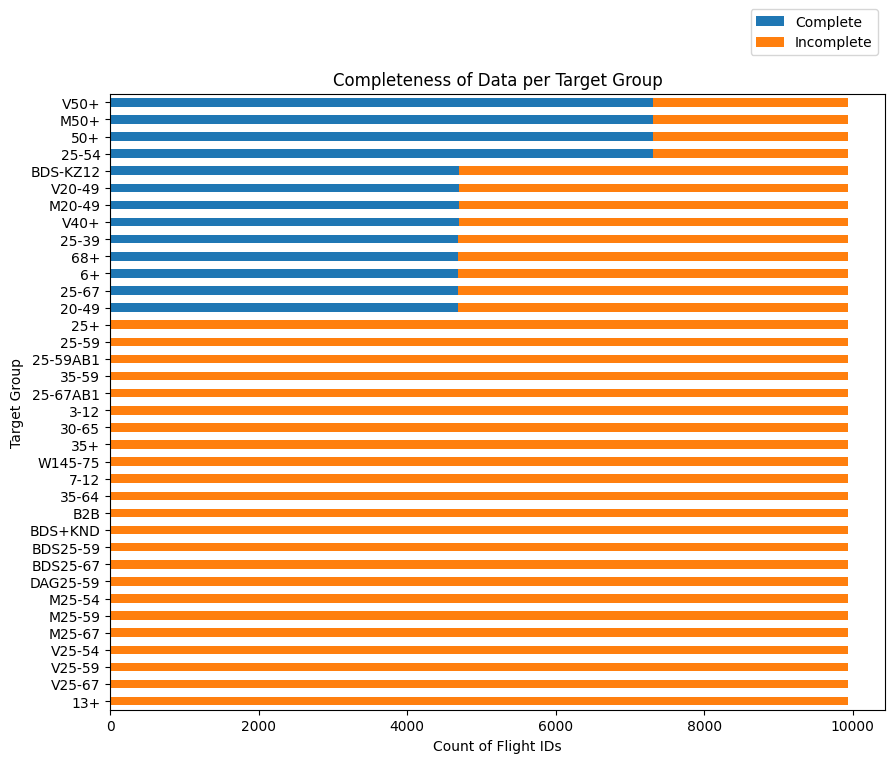

In [46]:
# Concatenate all results into one DataFrame
completeness_df = pd.concat(completeness_data, ignore_index=True)

# Pivot the DataFrame to have 'Complete' and 'Incomplete' as columns
pivot_df = completeness_df.pivot(index='target_group', columns='data_status', values='count_flights')

# Calculate completeness (ratio of Complete flights to Total flights)
pivot_df['Completeness'] = pivot_df['Complete'] / (pivot_df['Complete'] + pivot_df['Incomplete'])

# Sort by Completeness
pivot_df = pivot_df.sort_values(by='Completeness', ascending=True)

# Plotting the horizontal bar chart
plt.figure(figsize=(10, 8))
pivot_df[['Complete', 'Incomplete']].plot(kind='barh', stacked=True, ax=plt.gca())
plt.xlabel('Count of Flight IDs')
plt.ylabel('Target Group')
plt.title('Completeness of Data per Target Group')

# Move the legend outside of the plot
plt.legend(loc='center right', bbox_to_anchor=(1.0, 1.1))

plt.show()

In [45]:
# Concatenate all results into one DataFrame
completeness_df = pd.concat(completeness_data, ignore_index=True)

# Pivot the DataFrame to have 'Complete' and 'Incomplete' as columns
pivot_df = completeness_df.pivot(index='target_group', columns='data_status', values='count_flights').fillna(0)

# Calculate completeness (ratio of Complete flights to Total flights)
pivot_df['Completeness'] = pivot_df['Complete'] / (pivot_df['Complete'] + pivot_df['Incomplete'])

# Sort by Completeness
pivot_df = pivot_df.sort_values(by='Completeness', ascending=True)

# Plotting the horizontal bar chart
plt.figure(figsize=(12, 8))
ax = pivot_df[['Complete', 'Incomplete']].plot(kind='barh', stacked=True, ax=plt.gca())
plt.xlabel('Count of Flight IDs')
plt.ylabel('Target Group')
plt.title('Completeness of Data per Target Group')

# Move the legend outside of the plot
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

# Add percentage completeness at the end of each bar
for idx, row in pivot_df.iterrows():
    completeness = f"{row['Completeness']:.1%}"
    ax.text(row['Complete'] + row['Incomplete'] + 1, idx, completeness, va='center')

plt.tight_layout()
plt.show()

ConversionError: Failed to convert value(s) to axis units: '13+'

Error in callback <function _draw_all_if_interactive at 0x000001CDB7395580> (for post_execute):


ConversionError: Failed to convert value(s) to axis units: '13+'

ConversionError: Failed to convert value(s) to axis units: '13+'

<Figure size 1200x800 with 1 Axes>

In [ ]:
# Ensure all count_flights are numeric
completeness_df['count_flights'] = pd.to_numeric(completeness_df['count_flights'], errors='coerce').fillna(0)

# Pivot the DataFrame to have 'Complete' and 'Incomplete' as columns
pivot_df = completeness_df.pivot(index='target_group', columns='data_status', values='count_flights').fillna(0)

# Calculate completeness (ratio of Complete flights to Total flights)
pivot_df['Completeness'] = pivot_df['Complete'] / (pivot_df['Complete'] + pivot_df['Incomplete'])

# Sort by Completeness
pivot_df = pivot_df.sort_values(by='Completeness', ascending=True)

# Convert index to categorical type to ensure correct plotting
pivot_df.index = pd.Categorical(pivot_df.index, categories=pivot_df.index, ordered=True)

# Plotting the horizontal bar chart
plt.figure(figsize=(12, 8))
ax = pivot_df[['Complete', 'Incomplete']].plot(kind='barh', stacked=True, ax=plt.gca())
plt.xlabel('Count of Flight IDs')
plt.ylabel('Target Group')
plt.title('Completeness of Data per Target Group')

# Move the legend outside of the plot
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

# Add percentage completeness at the end of each bar
for idx, row in pivot_df.iterrows():
    completeness = f"{row['Completeness']:.1%}"
    total = row['Complete'] + row['Incomplete']
    ax.text(total + 0.1, idx, completeness, va='center')

plt.tight_layout()
plt.show()

ConversionError: Failed to convert value(s) to axis units: '13+'

Error in callback <function _draw_all_if_interactive at 0x000001CDB7395580> (for post_execute):


ConversionError: Failed to convert value(s) to axis units: '13+'

ConversionError: Failed to convert value(s) to axis units: '13+'

<Figure size 1200x800 with 1 Axes>